# 02 · Regresión Logística
**Responsable:** Paul Rosero

La lógica del modelo está en `src/models/logistic_regression.py` → función `construir_clasificador()`.
Este notebook solo entrena, evalúa, analiza y exporta usando el flujo común
(misma partición, mismo preprocesamiento y mismas métricas que los otros modelos).

In [1]:
# Configuración: permite importar el código común de src/ desde la carpeta notebooks/
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
plt.style.use("ggplot")
sns.set_palette("muted")

from src import config, data, evaluation
from src.training import entrenar_y_evaluar, exportar_final

CLAVE = "lr"

## 1. Datos

In [2]:
df = data.cargar_dataset()
print(df.shape)

(115231, 26)


## 2. Entrenamiento (80%) y evaluación (20%)

In [3]:
pipeline, metricas, (X_test, y_test) = entrenar_y_evaluar(CLAVE, df)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['url_len','dom_len','tld_len',...,'digit_ratio','spec_ratio','entropy']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [4]:
print(metricas["reporte"])
print({k: round(metricas[k], 4) for k in ("accuracy", "precision", "recall", "f1", "auc")})

              precision    recall  f1-score   support

 Benigna (0)       0.99      0.93      0.96     19729
Phishing (1)       0.69      0.92      0.79      3318

    accuracy                           0.93     23047
   macro avg       0.84      0.92      0.87     23047
weighted avg       0.94      0.93      0.93     23047

{'accuracy': 0.928, 'precision': 0.6863, 'recall': 0.9204, 'f1': 0.7863, 'auc': 0.9766}


## 3. Matriz de confusión

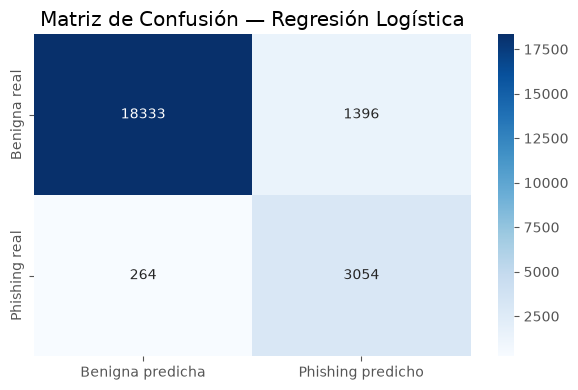

In [5]:
evaluation.graficar_matriz_confusion(metricas, f"Matriz de Confusión — {metricas['modelo']}")
plt.show()

**Interpretación** (conjunto de prueba: 23.047 URLs, 3.318 de phishing):

- **Verdaderos positivos (TP = 3.054):** URLs de phishing detectadas correctamente.
- **Falsos negativos (FN = 264):** phishing que el modelo dejó pasar. Es el error más grave en ciberseguridad,
  porque el usuario abriría el enlace confiado. El **Recall es 92,0 %**: de cada 100 ataques, el modelo detecta 92.
- **Falsos positivos (FP = 1.396):** URLs legítimas marcadas como phishing (falsas alarmas). Son muchas: la
  **Precision es solo 68,6 %**, es decir, casi 1 de cada 3 alertas es falsa. Con `class_weight="balanced"` el modelo
  prioriza no dejar pasar ataques, a costa de molestar al usuario con alertas innecesarias.
- **Verdaderos negativos (TN = 18.333):** URLs legítimas reconocidas como tales.

## 4. Curva ROC

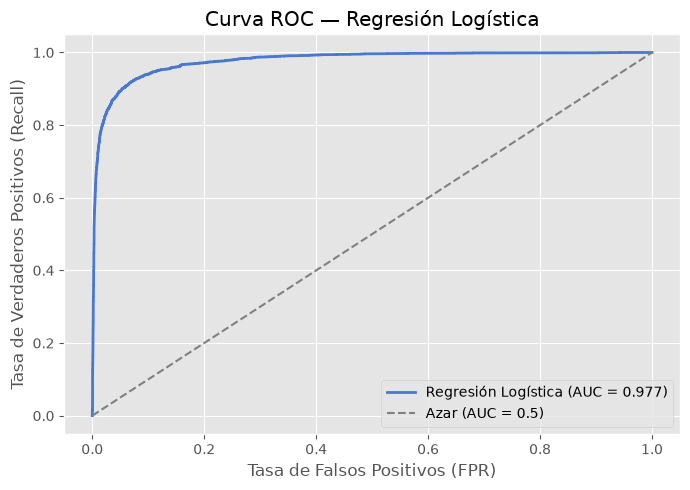

In [6]:
evaluation.graficar_roc({metricas["modelo"]: pipeline}, X_test, y_test, f"Curva ROC — {metricas['modelo']}")
plt.show()

## 5. Interpretación: coeficientes / odds-ratio
Como las variables están escaladas, cada coeficiente indica cuánto cambia el logaritmo de las *odds* de phishing
cuando la variable aumenta **una desviación estándar**, manteniendo las demás constantes.
El *odds ratio* (`exp(coef)`) se lee así: > 1 empuja hacia phishing, < 1 empuja hacia benigna.

In [7]:
# Coeficientes del modelo (variables ya escaladas)
modelo = pipeline.named_steps["modelo"]
coef = pd.Series(modelo.coef_[0], index=X_test.columns).sort_values()
display(pd.DataFrame({"coeficiente": coef, "odds_ratio": np.exp(coef)}))

,coeficiente,odds_ratio
path_len,-6.748571,0.001173
query_len,-6.286571,0.001861
dom_len,-2.252214,0.105166
subdom_cnt,-1.676807,0.186970
amp_cnt,-0.492184,0.611290
qm_cnt,-0.454817,0.634564
tld_len,-0.433571,0.648190
spec_ratio,-0.380118,0.683781
letter_ratio,-0.321735,0.724890
dot_cnt,-0.294318,0.745039


**Interpretación:**

- **Variables que empujan hacia phishing de forma consistente con el EDA:** `entropy` (OR ≈ 6,1), `is_https`
  (OR ≈ 3,6), `digit_cnt` (OR ≈ 3,2) y `digit_ratio` (OR ≈ 2,3). Las URLs más aleatorias, con más dígitos y con HTTPS
  aumentan la probabilidad de phishing, igual que mostraron las correlaciones del notebook `01`.
- **`dom_len` (OR ≈ 0,11) y `subdom_cnt` (OR ≈ 0,19)** empujan hacia benigna: con el resto constante, un dominio
  registrado más largo y con subdominios (`www.`, `ars.usda.gov`) es típico de sitios institucionales legítimos.
- **Coeficientes extremos por multicolinealidad:** `letter_cnt` (+4,96) y `url_len` (+4,20) frente a `path_len` (−6,75)
  y `query_len` (−6,29) se compensan entre sí. Son variables casi redundantes (`url_len` y `letter_cnt` tienen
  correlación 0,97, y la ruta y los parámetros forman parte de la longitud total), así que el modelo reparte el
  efecto entre ellas con signos opuestos. **No deben leerse por separado**: el efecto conjunto de "URL más larga" es
  hacia phishing. Para interpretar coeficientes individuales habría que eliminar variables redundantes o usar
  regularización L1.

## 6. Exportación (reentrenado con el 100% de los datos)

In [8]:
ruta = exportar_final(CLAVE, df)
print("Modelo exportado en:", ruta)

Modelo exportado en: models/modelo_lr.pkl


## 7. Conclusiones

- La Regresión Logística alcanza **AUC = 0,977**, así que separa bien las clases cuando se mira el ranking de
  probabilidades.
- Con el umbral de 0,5 y `class_weight="balanced"` logra un **Recall alto (92,0 %)**, pero una **Precision baja
  (68,6 %)** y un **F1 de 0,786**: detecta la mayoría de ataques, pero genera 1.396 falsas alarmas en la prueba.
- Es el modelo más **interpretable** (odds ratios) y el más liviano (≈ 2 KB), pero al ser lineal no capta
  combinaciones entre variables (por ejemplo, "URL larga **y** con muchos dígitos **y** HTTPS"), lo que limita su
  precisión.
- Sirve como **línea base** para comparar con el SVM lineal y el SVM gaussiano en el notebook `05`.